# ケース3：来年離れる顧客を先に見つける（顧客離反予測）
### 多分野データ解析実践演習 ― DSプロセス実践ノート（Online Retail II × 機械学習）

| 項目 | 内容 |
|---|---|
| データ | UCI *Online Retail II*（英国のオンライン雑貨卸・小売、2009/12〜2011/12、約107万行）CC BY 4.0 / Chen, D. (2012) https://doi.org/10.24432/C5CG6D |
| 問い | **「今年買ってくれた顧客のうち、来年1回も買わない人は誰か？」を、今年の購買データだけで先回りして当てる** |
| 手法 | RFM特徴量 ＋ 機械学習（ロジスティック回帰／ランダムフォレスト／勾配ブースティング） |
| 環境 | Google Colab（上から順に ▶ を押すだけで動きます） |

---
## このノートの地図（DSプロセス＝CRISP-DMの6ステップ）

| ステップ | このノートでやること | ビジネスの言葉で言うと |
|---|---|---|
| ① ビジネス理解 | 「離反」を定義する | 何を当てたら会社が助かる？ |
| ② データ理解 | 中身・欠損・おかしな値を見る | 帳簿はきれい？ |
| ③ 前処理 | キャンセル・重複・顧客ID欠損を整理 | 帳簿の清書 |
| ④ 特徴量づくり | 取引明細 → **顧客1人1行の表**（RFM） | 顧客カルテを作る |
| ⑤ モデリング | 3種類の機械学習モデルで学習 | 「離れそうな人の特徴」をAIに覚えさせる |
| ⑥ 評価・解釈・展開 | 精度・重要度・引き留めリスト | 結局、誰に何をする？ |

> 💡 **文系の方へ**：コードの中身を全部理解しなくて大丈夫です。各セルの前の説明文と、実行結果の「読み方」を中心に追ってください。

---
# ① ビジネス理解：「離反」をどう定義するか

「離反（churn）」は、サブスクのように**解約ボタン**があれば明確ですが、この店にはありません。顧客は**黙って来なくなる**だけです。
そこで、分析者が「離反」を**操作的に定義**する必要があります（ここがDSで一番大事な“設計”です）。

```
  観察期間（1年）                       予測期間（1年）
 |←──── 2009/12/01 〜 2010/11/30 ────→|←──── 2010/12/01 〜 2011/11/30 ────→|
   この期間の買い方から「特徴」を作る    ↑基準日   この期間に1回も買わなかったら「離反=1」
```

| 用語 | 定義 |
|---|---|
| 対象顧客 | 観察期間に1回以上購入した顧客（顧客IDあり） |
| 離反＝1 | 予測期間に**1回も購入しなかった** |
| 継続＝0 | 予測期間に1回以上購入した |

### ⚠️ 鉄則：「未来のデータ」を特徴量に混ぜない（リーケージ防止）
基準日（2010/12/01）より**後**の情報を特徴量に使うと、カンニングになり精度が不当に高く出ます。現場では「明日の行動」は見えないので、**基準日で時間を切る**のが絶対ルールです。

### 📌 なぜこれがビジネスになるのか
新規顧客の獲得コストは、既存顧客の維持コストの数倍かかると言われます。**離れてから慌てる**のではなく、**離れる前に**クーポン・営業電話・カタログ送付などで手を打つための「優先リスト」を作るのがゴールです。

---
# ② データ理解
## 2-0. 準備（日本語フォントとライブラリ）
グラフの日本語が「□□□」に化けないよう、最初に日本語フォントを入れます（30秒ほど）。

In [1]:
# --- 日本語フォント（Colab用。ローカルで既に入っていればスキップされます） ---
import subprocess, os, glob
if not glob.glob('/usr/share/fonts/**/NotoSansCJK*', recursive=True):
    subprocess.run('apt-get -qq -y install fonts-noto-cjk > /dev/null', shell=True)

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
for f in glob.glob('/usr/share/fonts/**/NotoSansCJK*.tt*', recursive=True):
    fm.fontManager.addfont(f)
plt.rcParams['font.family'] = 'Noto Sans CJK JP'
plt.rcParams['axes.unicode_minus'] = False

import numpy as np
import pandas as pd
pd.set_option('display.float_format', '{:,.2f}'.format)

# グラフの色（継続=青、離反=オレンジ で統一）
C_STAY, C_CHURN, INK, MUTED = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8})
print('準備OK')

準備OK


## 2-1. データを読み込む
**方法A（おすすめ）**：Googleドライブの `マイドライブ/online_retail_II.xlsx` に置いて読み込む
**方法B**：このあと表示される「ファイル選択」ボタンからアップロードする（43MBあるので数分かかります）

Excelファイルは年度ごとに**2シート**に分かれているので、両方読んで縦に結合します。
読み込みに1〜2分かかるため、2回目以降は高速な `parquet` 形式のキャッシュから読み込みます。

In [2]:
import os
DATA_XLSX = 'online_retail_II.xlsx'
CACHE = 'online_retail_II.parquet'

try:                                   # Colab上ならドライブをマウント
    from google.colab import drive, files
    IN_COLAB = True
    drive.mount('/content/drive')
    drive_path = '/content/drive/MyDrive/online_retail_II.xlsx'
    if os.path.exists(drive_path):
        DATA_XLSX = drive_path
        CACHE = '/content/drive/MyDrive/online_retail_II.parquet'
except ImportError:
    IN_COLAB = False

if os.path.exists(CACHE):
    raw = pd.read_parquet(CACHE)
    print('キャッシュから読み込みました')
else:
    if not os.path.exists(DATA_XLSX) and IN_COLAB:   # 方法B：アップロード
        print('online_retail_II.xlsx を選択してください')
        up = files.upload()
        DATA_XLSX = list(up.keys())[0]
    sheets = pd.read_excel(DATA_XLSX, sheet_name=None)   # 全シートを辞書で取得
    for name, s in sheets.items():
        print(f'シート「{name}」: {s.shape[0]:,} 行')
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw['Invoice'] = raw['Invoice'].astype(str)
    raw['StockCode'] = raw['StockCode'].astype(str)
    raw['Description'] = raw['Description'].astype('string')   # 数値と文字が混在しているので文字列に統一
    raw.to_parquet(CACHE)
    print('キャッシュを保存しました →', CACHE)

print(f'合計 {raw.shape[0]:,} 行 × {raw.shape[1]} 列')
raw.head()

キャッシュから読み込みました
合計 1,067,371 行 × 8 列


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


### 📖 列の意味（データ辞書）
| 列名 | 意味 | 注意点 |
|---|---|---|
| Invoice | 請求書番号（1回の注文） | **先頭が「C」ならキャンセル** |
| StockCode | 商品コード | 送料（POST）など商品でないコードも混在 |
| Description | 商品名 | |
| Quantity | 数量 | キャンセルはマイナス |
| InvoiceDate | 取引日時 | |
| Price | 単価（英ポンド £） | |
| Customer ID | 顧客番号 | **約2割が欠損**（ゲスト購入など） |
| Country | 国 | 約9割が英国 |

※ 1行＝「1回の注文の中の1商品」です。1人の顧客が何十行も持っています（**明細データ**）。

In [3]:
print('期間:', raw['InvoiceDate'].min(), '〜', raw['InvoiceDate'].max())
check = pd.DataFrame({
    '件数': [raw.duplicated().sum(),
             raw['Customer ID'].isna().sum(),
             raw['Invoice'].str.startswith('C').sum(),
             (raw['Quantity'] <= 0).sum(),
             (raw['Price'] <= 0).sum()]},
    index=['完全重複行', '顧客ID欠損', 'キャンセル行(C始まり)', '数量0以下', '単価0以下'])
check['割合(%)'] = check['件数'] / len(raw) * 100
check

期間: 2009-12-01 07:45:00 〜 2011-12-09 12:50:00


,件数,割合(%)
完全重複行,34335,3.22
顧客ID欠損,243007,22.77
キャンセル行(C始まり),19494,1.83
数量0以下,22950,2.15
単価0以下,6207,0.58


### 🔍 読み方
- **完全重複行が約3.4万行**：2つのシートが2010/12/01〜12/09で**重なっている**のが主な原因です。そのまま結合すると同じ取引を二重に数えてしまいます。
- **顧客IDの欠損が約23%**：「誰が買ったか」が分からない行は、顧客単位の分析には使えません。
- **キャンセル・マイナス数量**：「買った」ではなく「取り消した」記録。購入額から分けて扱います。

> データの約7〜8割の時間は前処理に使う、と言われる理由がここにあります。

---
# ③ 前処理（帳簿の清書）

In [4]:
df = raw.drop_duplicates().copy()                       # 重複を除く
df = df.rename(columns={'Customer ID': 'CustomerID'})
df = df.dropna(subset=['CustomerID'])                   # 顧客IDがない行を除く
df['CustomerID'] = df['CustomerID'].astype(int)
df['IsCancel'] = df['Invoice'].str.startswith('C')      # キャンセルの目印
df['Amount'] = df['Quantity'] * df['Price']             # 明細ごとの金額

print(f'前処理後: {len(df):,} 行（元の {len(df)/len(raw):.0%}）')
print(f'顧客数: {df.CustomerID.nunique():,} 人')

前処理後: 797,885 行（元の 75%）
顧客数: 5,942 人


## 3-1. 時間で切る（観察期間 と 予測期間）

In [5]:
CUTOFF = pd.Timestamp('2010-12-01')   # 基準日：ここで時間を切る
END    = pd.Timestamp('2011-12-01')   # 予測期間の終わり（ちょうど1年後）

obs = df[df['InvoiceDate'] < CUTOFF]                                  # 観察期間（過去）
fut = df[(df['InvoiceDate'] >= CUTOFF) & (df['InvoiceDate'] < END)]   # 予測期間（未来）

buy  = obs[(~obs.IsCancel) & (obs.Quantity > 0) & (obs.Price > 0)]   # 観察期間の「購入」
canc = obs[obs.IsCancel]                                              # 観察期間の「キャンセル」
print(f'観察期間の購入明細: {len(buy):,} 行 / 予測期間の明細: {len(fut):,} 行')

観察期間の購入明細: 386,732 行 / 予測期間の明細: 384,222 行


---
# ④ 特徴量づくり：明細データ → 顧客カルテ（1人1行）

機械学習は「1行＝1人」の表でないと学習できません。そこで明細を**顧客ごとに集計**します。
あとで「2012年の予測」にも同じ手順を使い回せるよう、**関数（make_features）**にしておきます。
マーケティングの定番 **RFM分析** をベースに、いくつか追加します。

| 特徴量 | 意味 | 直感（離反との関係） |
|---|---|---|
| **R** recency_days | 最終購入から基準日までの日数 | 長いほど「もう来ない」かも |
| **F** frequency | 注文回数 | 多いほど常連 |
| **M** monetary | 購入金額合計（£） | 多いほど上得意 |
| tenure_days | 初回購入から基準日までの日数 | 付き合いの長さ |
| n_products | 買った商品の種類数 | 品揃えへの依存度 |
| active_months | 購入があった月の数 | 定期的に来ているか |
| avg_order_value | 1注文あたり平均額 | 卸売的な大口か |
| monetary_last90 | 直近90日の購入額 | **最近の勢い** |
| share_last90 | 購入額のうち直近90日の割合 | 最近増えているか減っているか |
| n_cancel / cancel_rate | キャンセル回数・比率 | 不満のサイン？ |
| is_uk | 主な購入国が英国か | 海外は離れやすい？ |

In [6]:
def make_features(df, cutoff):
    '''基準日 cutoff の「直前1年間」だけを使って、顧客1人1行の特徴量表を作る'''
    win  = df[(df['InvoiceDate'] >= cutoff - pd.Timedelta(days=365)) & (df['InvoiceDate'] < cutoff)]
    buy  = win[(~win.IsCancel) & (win.Quantity > 0) & (win.Price > 0)]
    canc = win[win.IsCancel]
    g = buy.groupby('CustomerID')
    feat = pd.DataFrame({
        'recency_days':  (cutoff - g['InvoiceDate'].max()).dt.days,
        'frequency':     g['Invoice'].nunique(),
        'monetary':      g['Amount'].sum(),
        'tenure_days':   (cutoff - g['InvoiceDate'].min()).dt.days,
        'n_products':    g['StockCode'].nunique(),
        'active_months': g['InvoiceDate'].apply(lambda s: s.dt.to_period('M').nunique()),
    })
    feat['avg_order_value'] = feat['monetary'] / feat['frequency']
    last90 = buy[buy['InvoiceDate'] >= cutoff - pd.Timedelta(days=90)].groupby('CustomerID')['Amount'].sum()
    feat['monetary_last90'] = last90.reindex(feat.index).fillna(0)
    feat['share_last90']    = feat['monetary_last90'] / feat['monetary']
    feat['n_cancel']    = canc.groupby('CustomerID')['Invoice'].nunique().reindex(feat.index).fillna(0)
    feat['cancel_rate'] = feat['n_cancel'] / (feat['frequency'] + feat['n_cancel'])
    main_country = buy.groupby('CustomerID')['Country'].agg(lambda s: s.mode()[0])
    feat['is_uk'] = (main_country == 'United Kingdom').astype(int)
    return feat

feat = make_features(df, CUTOFF)    # 2010/12/01 時点の顧客カルテ

# ---- 正解ラベル：予測期間に1回も買わなければ離反=1 ----
future_buyers = set(fut[(~fut.IsCancel) & (fut.Quantity > 0)]['CustomerID'])
feat['churn'] = (~feat.index.isin(future_buyers)).astype(int)

print(f'対象顧客: {len(feat):,} 人 / 離反率: {feat.churn.mean():.1%}')
feat.head()

対象顧客: 4,266 人 / 離反率: 36.4%


,recency_days,frequency,monetary,tenure_days,n_products,active_months,avg_order_value,monetary_last90,share_last90,n_cancel,cancel_rate,is_uk,churn
CustomerID,,,,,,,,,,,,,
12346,155,11,372.86,351,26,4,33.90,0.00,0.00,4.00,0.27,1,0
12347,30,1,611.53,30,40,1,611.53,611.53,1.00,0.00,0.00,0,0
12348,64,1,222.16,64,20,1,222.16,222.16,1.00,0.00,0.00,0,0
12349,33,3,"2,671.14",215,90,3,890.38,"1,402.62",0.53,1.00,0.25,0,0
12351,1,1,300.93,1,21,1,300.93,300.93,1.00,0.00,0.00,0,1


### 🔍 読み方
約4,300人のうち**約36%が翌年1回も買っていない**ことが分かりました。3人に1人が黙って去っている、というのがこの会社の現状です。

---
## 4-1. 探索的データ分析（EDA）：離反した人と継続した人はどこが違う？
モデルを作る前に、**人間の目で**違いを確かめます。ここで「仮説」を持っておくと、後でモデルの結果を解釈しやすくなります。

In [7]:
comp = feat.groupby('churn').median().T
comp.columns = ['継続(0)の中央値', '離反(1)の中央値']
comp

,継続(0)の中央値,離反(1)の中央値
recency_days,33.00,102.00
frequency,3.00,1.00
monetary,"1,066.30",347.54
tenure_days,261.00,208.00
n_products,51.00,22.00
active_months,3.00,1.00
avg_order_value,310.30,231.34
monetary_last90,416.85,0.00
share_last90,0.38,0.00
n_cancel,0.00,0.00


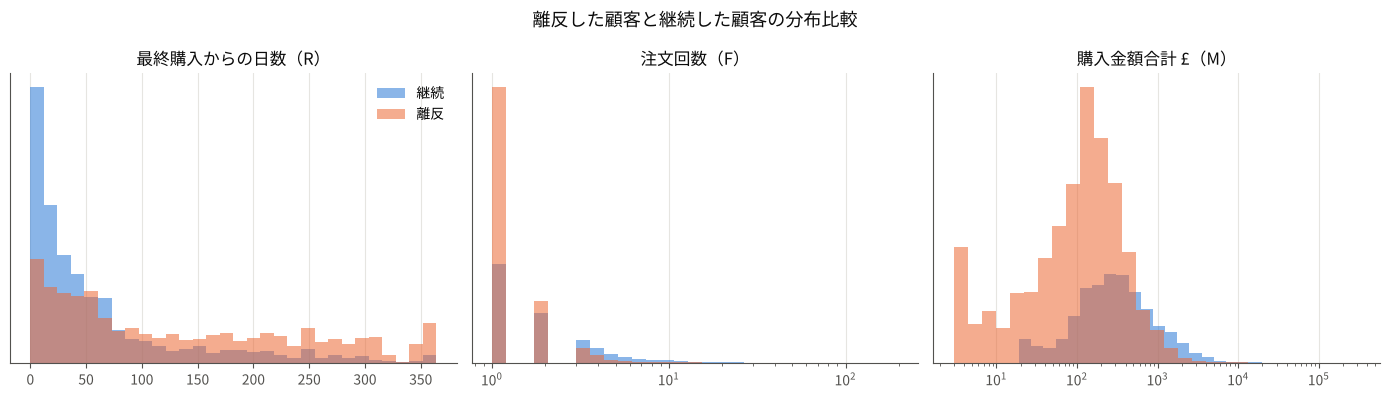

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
items = [('recency_days', '最終購入からの日数（R）', False),
         ('frequency', '注文回数（F）', True),
         ('monetary', '購入金額合計 £（M）', True)]
for ax, (col, title, logx) in zip(axes, items):
    for lab, color, name in [(0, C_STAY, '継続'), (1, C_CHURN, '離反')]:
        v = feat.loc[feat.churn == lab, col]
        bins = np.logspace(np.log10(max(v.min(), 1)), np.log10(feat[col].max() + 1), 30) if logx else 30
        ax.hist(v.clip(lower=1) if logx else v, bins=bins, alpha=0.55, color=color, label=name, density=True)
    if logx: ax.set_xscale('log')
    ax.set_title(title, color=INK); ax.set_yticks([])
axes[0].legend(frameon=False)
plt.suptitle('離反した顧客と継続した顧客の分布比較', color=INK, fontsize=13)
plt.tight_layout(); plt.show()

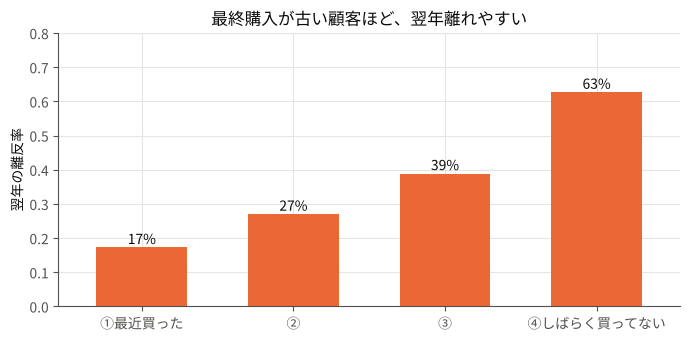

In [9]:
# R（最近性）を4段階に分けて、離反率を比べる
feat['R_group'] = pd.qcut(feat['recency_days'], 4,
                          labels=['①最近買った', '②', '③', '④しばらく買ってない'])
rate = feat.groupby('R_group', observed=True)['churn'].mean()
ax = rate.plot.bar(color=C_CHURN, width=0.6, rot=0, figsize=(7, 3.5))
for i, v in enumerate(rate): ax.text(i, v + 0.01, f'{v:.0%}', ha='center', color=INK)
ax.set_ylabel('翌年の離反率'); ax.set_xlabel(''); ax.set_ylim(0, 0.8)
ax.set_title('最終購入が古い顧客ほど、翌年離れやすい', color=INK)
plt.tight_layout(); plt.show()
feat = feat.drop(columns='R_group')

### 🔍 読み方（仮説）
- 離反した人は、**最終購入が古く（R大）・回数が少なく（F小）・金額が小さい（M小）**。RFMの直感どおりです。
- 特に「最近買ったグループ」と「しばらく買ってないグループ」で離反率が大きく違います。
- 👉 仮説：「**一見さん（1回だけ購入）**」と「**最近ご無沙汰の人**」が離反の中心では？ これをモデルで確かめます。

---
# ⑤ モデリング（機械学習）

## 5-1. 学習用とテスト用に分ける
**模試と本番の関係**です。学習用（75%）でモデルに勉強させ、テスト用（25%）は**本番まで一度も見せない**ことで、「初めて見る顧客」への実力を正しく測ります。

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

X = feat.drop(columns='churn')
y = feat['churn']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)   # stratify=離反率を揃えて分割
print(f'学習用 {len(X_train):,} 人 / テスト用 {len(X_test):,} 人')

学習用 3,199 人 / テスト用 1,067 人


## 5-2. まず「何もしないモデル」と比べる（ベースライン）
「全員“継続”と答えるだけ」でも正解率は約64%になります。**正解率だけを見るとAIの実力を見誤る**ので、ベースラインとの比較が必須です。

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'全員「継続」と答えた場合の正解率: {accuracy_score(y_test, dummy.predict(X_test)):.1%}')
print('→ しかし離反者を1人も見つけられていない（使い物にならない）')

全員「継続」と答えた場合の正解率: 63.6%
→ しかし離反者を1人も見つけられていない（使い物にならない）


## 5-3. 3つの機械学習モデルを比較する

| モデル | イメージ | 長所 | 短所 |
|---|---|---|---|
| **ロジスティック回帰** | 各特徴に「点数」をつけて足し合わせ、確率に変換 | 説明しやすい | 複雑な関係は苦手 |
| **ランダムフォレスト** | たくさんの決定木（Yes/Noの質問の木）の**多数決** | 安定・頑健 | 中身が見えにくい |
| **勾配ブースティング** | 前の木の**間違いを次の木が修正**していく | 高精度になりやすい | 過学習しやすい |

評価には **AUC**（0.5=サイコロ、1.0=完璧）を使います。「離反者と継続者を1人ずつランダムに選んだとき、離反者の方を“より危ない”と正しく順位づけできる確率」です。
さらに **5分割交差検証（CV）**：学習用データを5つに分け、「4つで学習→1つで採点」を5回繰り返して平均します（1回の模試より5回の模試の平均が信頼できる）。

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    'ロジスティック回帰': make_pipeline(FunctionTransformer(np.log1p),   # 金額の偏りを対数でならす
                                     StandardScaler(), LogisticRegression(max_iter=1000)),
    'ランダムフォレスト': RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                              max_features=0.5, random_state=42, n_jobs=-1),
    '勾配ブースティング': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.03, max_depth=3,
                                                     min_samples_leaf=40, l2_regularization=1.0,
                                                     random_state=42),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc')
    m.fit(X_train, y_train)
    test_auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    rows.append([name, s.mean(), s.std(), test_auc])
result = pd.DataFrame(rows, columns=['モデル', 'CV平均AUC', 'CVのばらつき', 'テストAUC']).set_index('モデル')
result.round(3)

,CV平均AUC,CVのばらつき,テストAUC
モデル,,,
ロジスティック回帰,0.79,0.01,0.79
ランダムフォレスト,0.78,0.01,0.78
勾配ブースティング,0.78,0.01,0.79


### 🔍 読み方
- 3モデルとも **AUC ≈ 0.78** 前後で、差はごくわずか（ばらつきの範囲内）。
- 👉 **教訓：「複雑なAIほど強い」とは限らない。** 精度を決めたのはモデルの種類よりも、④で作った**特徴量（顧客カルテの質）**です。
- 以降は、精度と安定性のバランスがよく、重要度も出せる **ランダムフォレスト** を主役にします（どれを選んでも結論はほぼ同じです）。

---
# ⑥ 評価・解釈・展開
## 6-1. 混同行列：当たり・外れの内訳

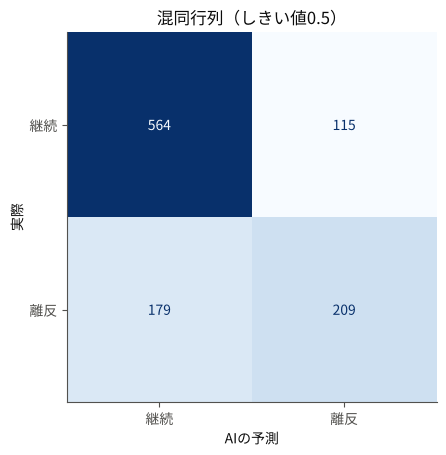

              precision    recall  f1-score   support

          継続      0.759     0.831     0.793       679
          離反      0.645     0.539     0.587       388

    accuracy                          0.724      1067
   macro avg      0.702     0.685     0.690      1067
weighted avg      0.718     0.724     0.718      1067



In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
best = models['ランダムフォレスト']
proba = best.predict_proba(X_test)[:, 1]          # 離反確率（0〜1）
pred = (proba >= 0.5).astype(int)                 # 50%以上なら「離反」と判定

cm = confusion_matrix(y_test, pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['継続', '離反'])
disp.plot(cmap='Blues', colorbar=False); plt.grid(False)
plt.xlabel('AIの予測'); plt.ylabel('実際'); plt.title('混同行列（しきい値0.5）', color=INK)
plt.show()
print(classification_report(y_test, pred, target_names=['継続', '離反'], digits=3))

### 🔍 読み方
| 用語 | 意味 | 引き留め施策での意味 |
|---|---|---|
| **適合率 precision** | 「離反」と予測した人のうち、本当に離反した割合 | クーポンの**ムダ打ち**の少なさ |
| **再現率 recall** | 本当に離反した人のうち、AIが見つけられた割合 | **取りこぼし**の少なさ |

両者はトレードオフです。しきい値を下げれば取りこぼしは減るが、ムダ打ちが増えます。**どちらを優先するかはビジネス判断**（施策コスト次第）です。

## 6-2. 現場で使う形：「危ない順」リストの上位だけに手を打つ
現実には予算が限られるので、「全員に連絡」ではなく**離反確率の高い順に上位○%だけ**に施策を打ちます。そのとき、どれだけ当たるかを見ます（**リフト**＝ランダムに選ぶより何倍当たるか）。

In [14]:
r = pd.DataFrame({'actual': y_test.values, 'proba': proba}).sort_values('proba', ascending=False)
base = r['actual'].mean()
rows = []
for k in [0.1, 0.2, 0.3, 0.5]:
    top = r.head(int(len(r) * k))
    rows.append([f'上位{int(k*100)}%', len(top), top.actual.mean(),
                 top.actual.sum() / r.actual.sum(), top.actual.mean() / base])
lift = pd.DataFrame(rows, columns=['対象', '人数', '適合率(当たり率)', '再現率(カバー率)', 'リフト(倍)']).set_index('対象')
print(f'ランダムに選んだ場合の当たり率 = {base:.1%}')
lift.round(2)

ランダムに選んだ場合の当たり率 = 36.4%


,人数,適合率(当たり率),再現率(カバー率),リフト(倍)
対象,,,,
上位10%,106,0.76,0.21,2.10
上位20%,213,0.67,0.37,1.85
上位30%,320,0.65,0.53,1.78
上位50%,533,0.56,0.77,1.55


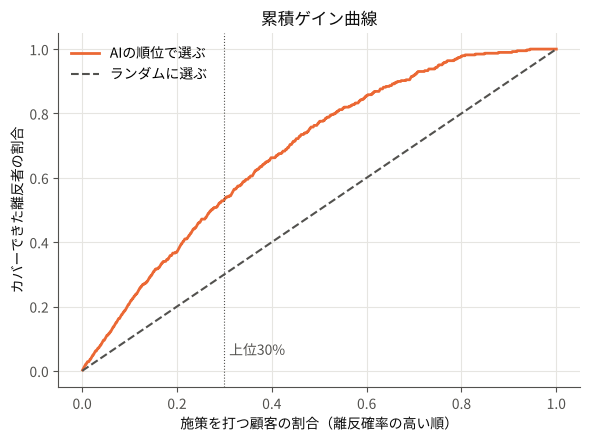

In [15]:
# 累積ゲイン曲線：上位何%に手を打てば、離反者の何%をカバーできるか
pct = np.arange(1, len(r) + 1) / len(r)
gain = r['actual'].cumsum().values / r['actual'].sum()
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(pct, gain, color=C_CHURN, lw=2, label='AIの順位で選ぶ')
ax.plot([0, 1], [0, 1], color=MUTED, lw=1.5, ls='--', label='ランダムに選ぶ')
ax.axvline(0.3, color=MUTED, lw=0.8, ls=':')
ax.text(0.31, 0.05, '上位30%', color=MUTED)
ax.set_xlabel('施策を打つ顧客の割合（離反確率の高い順）'); ax.set_ylabel('カバーできた離反者の割合')
ax.set_title('累積ゲイン曲線', color=INK); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 🔍 読み方
- 上位10%に絞ると当たり率は**ランダム（約36%）の約2倍**、上位30%でも約1.8倍で、**離反者の約半分**をカバーできます。
- オレンジの線が点線（ランダム）より上にあるほど、AIで順位づけする価値があります。

## 6-3. 解釈：AIは何を手がかりに「離反しそう」と判断したか
**順列重要度（Permutation Importance）**：ある特徴量の列だけをシャッフルして“でたらめ”にしたとき、精度（AUC）がどれだけ下がるかを測ります。大きく下がる＝その特徴量に頼っている、という意味です。

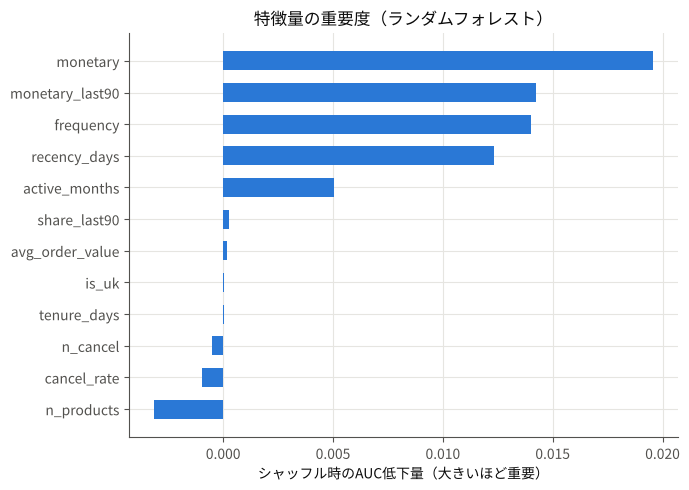

In [16]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=C_STAY, height=0.6)
ax.set_xlabel('シャッフル時のAUC低下量（大きいほど重要）')
ax.set_title('特徴量の重要度（ランダムフォレスト）', color=INK)
plt.tight_layout(); plt.show()

In [17]:
# ロジスティック回帰の係数：プラス=離反しやすくする、マイナス=引き留める方向
lr = models['ロジスティック回帰']
coef = pd.Series(lr[-1].coef_[0], index=X.columns).sort_values()
pd.DataFrame({'係数（標準化後）': coef, '向き': np.where(coef > 0, '↑離反しやすい', '↓継続しやすい')})

,係数（標準化後）,向き
monetary_last90,-0.37,↓継続しやすい
frequency,-0.32,↓継続しやすい
monetary,-0.31,↓継続しやすい
active_months,-0.29,↓継続しやすい
cancel_rate,-0.12,↓継続しやすい
n_products,-0.05,↓継続しやすい
tenure_days,-0.03,↓継続しやすい
avg_order_value,-0.02,↓継続しやすい
n_cancel,0.00,↑離反しやすい
is_uk,0.02,↑離反しやすい


### 🔍 読み方
- **累計金額（M）・直近90日の購入額・注文回数（F）・最終購入からの日数（R）**が主な手がかり（ロジスティック回帰の係数でも同じ顔ぶれ）。
- つまりAIは「**最近の勢いが落ちている／そもそも取引が浅い**顧客」を危ないと見ています。EDAの仮説と一致しました。
- 重要度がほぼ0やマイナスの特徴量（キャンセル率・商品種類数など）は、この問題では役に立っていない＝**削っても精度は落ちない**候補です。
- ⚠️ **注意：これは「相関」であって「原因」ではありません。** 「Rが大きいから離れる」のではなく、「離れつつある人はRが大きくなる」のかもしれません（→ 発展課題：因果推論）。

## 6-4. 費用対効果のざっくり試算（施策を打つ価値はあるか？）
テスト用の顧客（AIが一度も見ていない1,067人）で、「**期待損失＝離反確率×年間購入額**」の大きい順に施策を打ったらどうなるかを試算します。
仮定の数字（コスト・引き留め率）は**チームで議論して変えてください**（ここがビジネス設計の腕の見せどころ）。

In [18]:
COST_PER_CUSTOMER = 10     # 1人あたり施策コスト（£）：クーポン・人件費など【仮定】
SAVE_RATE = 0.20           # 施策を打った離反予定者のうち、引き留められる割合【仮定】

t = X_test.copy()
t['churn'] = y_test
t['churn_proba'] = proba
t['expected_loss'] = t['churn_proba'] * t['monetary']     # 放っておくと失いそうな売上の見込み
t = t.sort_values('expected_loss', ascending=False)

rows = []
for k in [0.1, 0.2, 0.3, 0.5, 1.0]:
    tgt = t.head(int(len(t) * k))
    saved = (tgt['churn'] * tgt['monetary']).sum() * SAVE_RATE   # 守れた売上（前年の購入額で近似）
    cost = len(tgt) * COST_PER_CUSTOMER
    rows.append([f'上位{int(k*100)}%', len(tgt), saved, cost, saved - cost, saved / cost])
roi = pd.DataFrame(rows, columns=['対象', '人数', '守れた売上£', '施策コスト£', '差引£', '費用対効果(倍)']).set_index('対象')
roi.round(1)

,人数,守れた売上£,施策コスト£,差引£,費用対効果(倍)
対象,,,,,
上位10%,106,"34,713.90",1060,"33,653.90",32.70
上位20%,213,"41,229.80",2130,"39,099.80",19.40
上位30%,320,"46,948.80",3200,"43,748.80",14.70
上位50%,533,"55,838.80",5330,"50,508.80",10.50
上位100%,1067,"68,035.40",10670,"57,365.40",6.40


### 🔍 読み方
- **費用対効果（倍）**は上位に絞るほど高い＝AIの順位づけが「お金の使い方」を効率化している証拠です。
- 一方、**差引の総額**は対象を広げても増え続けることがあります。どこで止めるかは「あと1人増やしたときの増分（限界効果）がコストを上回るか」で判断します。
- コストを £50（営業担当が訪問）に変えると結論はどう変わる？ → 実際に数字を変えて試してみましょう。

## 6-5. 展開：本番の「来年（2012年）離れそうな顧客」リストを作る
ここまでは「答え合わせができる過去（2011年）」で練習しました。いよいよ本番です。
**データの最終日（2011/12/09）の翌日を基準日**にして直近1年の顧客カルテを作り、**まだ誰も答えを知らない2012年**の離反確率を予測します。
さらに **リスクの高さ × 顧客の価値** で4つに分け、施策を出し分けます。

| | 価値が高い（購入額 上位25%） | 価値がふつう |
|---|---|---|
| **離反リスク高（確率≥50%）** | A：最優先で引き留め（担当者が個別連絡） | B：低コスト施策（メール・クーポン） |
| **離反リスク低** | C：優良顧客として維持（特典・先行案内） | D：通常対応 |

In [19]:
# ① 練習で選んだ設定のまま、全データ（学習用＋テスト用）で学習し直す
final = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.5,
                               random_state=42, n_jobs=-1).fit(X, y)

# ② 2011/12/10 を基準日に、直近1年の顧客カルテを作る（作り方は④と全く同じ関数）
NEXT_CUTOFF = pd.Timestamp('2011-12-10')
feat_2012 = make_features(df, NEXT_CUTOFF)

# ③ 2012年の離反確率を予測
scored = feat_2012.copy()
scored['churn_proba'] = final.predict_proba(feat_2012[X.columns])[:, 1]
scored['expected_loss'] = scored['churn_proba'] * scored['monetary']
print(f'予測対象: 2011年に購入した {len(scored):,} 人（2012年に離れるかは、まだ誰も知らない）')

value_line = scored['monetary'].quantile(0.75)
def segment(row):
    high_risk, high_value = row.churn_proba >= 0.5, row.monetary >= value_line
    if high_risk and high_value: return 'A: 最優先で引き留め'
    if high_risk:                return 'B: 低コスト施策'
    if high_value:               return 'C: 優良顧客として維持'
    return 'D: 通常対応'
scored['segment'] = scored.apply(segment, axis=1)

summary = scored.groupby('segment').agg(人数=('churn_proba', 'size'),
                                         平均離反確率=('churn_proba', 'mean'),
                                         年間購入額合計=('monetary', 'sum'),
                                         期待損失合計=('expected_loss', 'sum'))
display(summary.round(2))

out = scored.sort_values('expected_loss', ascending=False)[
    ['segment', 'churn_proba', 'monetary', 'expected_loss', 'recency_days', 'frequency']]
out.to_csv('churn_priority_list_2012.csv', encoding='utf-8-sig')   # Excelで文字化けしない形式
print('引き留め優先リスト（期待損失の大きい順）上位10人:')
out.head(10).round(2)

予測対象: 2011年に購入した 4,264 人（2012年に離れるかは、まだ誰も知らない）


,人数,平均離反確率,年間購入額合計,期待損失合計
segment,,,,
A: 最優先で引き留め,35,0.58,"253,523.17","162,736.76"
B: 低コスト施策,1328,0.66,"393,276.25","244,218.28"
C: 優良顧客として維持,1031,0.08,"6,522,485.61","318,776.57"
D: 通常対応,1870,0.31,"1,407,285.49","390,048.98"


引き留め優先リスト（期待損失の大きい順）上位10人:


,segment,churn_proba,monetary,expected_loss,recency_days,frequency
CustomerID,,,,,,
12346,A: 最優先で引き留め,0.74,"77,183.60","56,753.21",325,1
16446,C: 優良顧客として維持,0.22,"168,472.50","36,875.20",0,2
15749,A: 最優先で引き留め,0.64,"44,534.30","28,471.37",235,3
15098,A: 最優先で引き留め,0.63,"39,916.50","25,040.05",182,3
12590,A: 最優先で引き留め,0.61,"9,864.26","5,990.80",211,2
13093,A: 最優先で引き留め,0.54,"7,033.07","3,830.70",275,7
12980,C: 優良顧客として維持,0.48,"7,374.90","3,522.95",157,9
18102,C: 優良顧客として維持,0.02,"231,822.69","3,502.42",0,56
14646,C: 優良顧客として維持,0.01,"280,206.02","3,415.46",1,73


In [20]:
# Colabなら、作ったリストをPCにダウンロード
if IN_COLAB:
    files.download('churn_priority_list_2012.csv')

### 🔍 読み方
- **Aグループ**は人数が少ないのに期待損失が大きい＝**少人数に手厚く**が効く層。
- **Cグループ**は離反確率は低くても売上の大半を占めるので、「離反予測」とは別に**守りの施策**が必要です。
- ⚠️ **AIのリストを鵜呑みにしない**：上位に出てくる顧客 12346・16446 は、このデータで有名な「**巨額注文 → 直後に全量キャンセル**」の顧客です。今回の金額（monetary）はキャンセルを差し引いていないため、価値が過大に見えています。**最後は人間が中身を確認する**のが現場のルールです（→ 発展課題2：キャンセルを差し引いた「純購入額」に直してみよう）。
- このCSVが、営業・マーケ担当に渡す最終成果物（＝DSの「展開」）です。

---
# まとめ：発表スライド用の骨子（中間発表テンプレート）

| DSステップ | 発表で言うこと（例） |
|---|---|
| ① 課題設定 | 顧客の約36%が翌年黙って離れる。離れる**前に**手を打つため、離反予測モデルを作る |
| ② データ理解 | 107万行の取引明細。顧客ID欠損23%・キャンセル・シート重複を確認 |
| ③ 前処理 | 重複除去・ID欠損除外・キャンセル分離。基準日で時間を切りリーケージ防止 |
| ④ 特徴量 | RFM＋直近90日購入額など12個の顧客カルテ |
| ⑤ モデル | 3モデル比較でAUC≈0.78。モデル差は小さく、特徴量が効いた |
| ⑥ 評価・展開 | 上位30%で離反者の約半分をカバー。2012年の離反確率を全顧客に付け、リスク×価値の4セグメントで施策を出し分け |

## 限界（正直に書くと評価が上がります）
1. **ランダム分割の検証**：同じ時期の顧客でテストしています。本当は「2011年に作ったモデルで2012年を当てる」**時間をずらした検証**が理想（データが2年分しかないため今回は省略）。
2. **相関≠因果**：重要度は「目印」であって、「施策を打てば離反が減るか」は分かりません。
3. **「離反」の定義依存**：卸売業者は季節的に買うため、1年空いても戻る可能性があります。

---
# 🚀 発展課題（チームで1つ選んで深掘り）

| # | 課題 | ヒント |
|---|---|---|
| 1 | **定義を変えてみる**：観察6か月・予測6か月にすると結果はどう変わる？ | `CUTOFF`, `END` を変えるだけ。時間をずらした検証もできるようになる |
| 2 | **特徴量を改良・追加**：キャンセルを差し引いた純購入額、曜日・時間帯、商品カテゴリ、購入間隔のばらつき | 「卸売っぽさ」をどう数値化する？ |
| 3 | **しきい値をビジネスで決める**：6-5の仮定から「利益最大」のしきい値を探す | `for` 文で0.1〜0.9を総当たり |
| 4 | **因果AI（アップリフトモデリング）**：「施策を打つと**行動が変わる**人」だけを狙う | 「放っておいても残る人」「何をしても去る人」に施策はムダ。A/Bテスト設計とセット |
| 5 | **ベイズ推論（BG/NBDモデル）**：「まだ生きている確率 P(alive)」を確率モデルで推定し、機械学習と比較 | `lifetimes` / `pymc-marketing` ライブラリ |
| 6 | **強化学習の視点**：「いつ・誰に・どの施策を打つか」を逐次意思決定として定式化 | 状態＝顧客カルテ、行動＝施策、報酬＝売上−コスト |

> **OODAループで回そう**：Observe（データを見る）→ Orient（仮説を立てる）→ Decide（定義・特徴量を決める）→ Act（モデルを回す）→ 結果を見て再びObserve。一発で完璧を目指さず、小さく速く回すのがPBLのコツです。